In [1]:
import torch
import torch.nn as nn
from torchvision import transforms
import matplotlib.pyplot as plt
from tqdm import tqdm
from IPython.display import clear_output
import random
from torch.utils.data import Dataset, DataLoader
import os
from glob import glob
from PIL import Image
import json
from utils import moving_average

In [2]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

print(f"Using device: {device}")

# Choisir le GPU et vérifier
torch.cuda.set_device(0)
print(torch.cuda.current_device())  # doit afficher le numéro choisi dans torch.cuda.set_device()
print(torch.cuda.get_device_name(torch.cuda.current_device()))

Using device: cuda
0
Tesla V100S-PCIE-32GB


In [3]:
batch_size = 512
n_epochs = 10
n_classes = 5
crop_size = 32

In [4]:
class ImageDataset(Dataset):

    def __init__(self, split, transform=None):
        self.transform = transform

        # get the dictionnary with the crop's infos
        with open(f'data/dataset_crops/{split}_{crop_size}x{crop_size}_data.json', 'r', encoding='utf-8') as f:
            dico = json.load(f)

        # get all image paths, attributs and classes
        self.data = []

        for path in glob(os.path.join(f"data/dataset_crops/{split}", "**", "*.png"), recursive=True):
            filename = os.path.basename(path)      # "crop_i.png"
            crop_name = os.path.splitext(filename)[0]   # "crop_i"

            attributs = dico[crop_name]["attributs"]
            damage = dico[crop_name]["niveau de brûlé"]

            self.data.append((path, attributs, damage))


    def __len__(self):
        return len(self.data)


    def __getitem__(self, idx):
        img_path, attribut, label = self.data[idx]

        img = Image.open(img_path).convert("RGB")

        if self.transform is not None:
            img = self.transform(img)

        attribut = torch.tensor(attribut, dtype=torch.float32)
        label = torch.tensor(label, dtype=torch.int64)

        return img, attribut, label


# transformations ajoutées pour faire de la data augmentation autrement il y a de l'overfitting

def random_90_rotation(img):
    angles = [0, 90, 180, 270]
    return transforms.functional.rotate(img, angle=random.choice(angles))

transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.Lambda(random_90_rotation),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

train_dataset = ImageDataset(split="train", transform=transform)
val_dataset = ImageDataset(split="val", transform=transform)

In [5]:
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=8)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=True, num_workers=4)

train_iterator = iter(train_loader)
val_iterator = iter(val_loader)

In [6]:
from torchvision.models import resnet18

resnet = resnet18(weights=None)

# remplacer la dernière couche pour avoir le bon nombre de classe et pas les 1000 de ImageNet
in_features = resnet.fc.in_features
resnet.fc = nn.Linear(in_features, n_classes)


resnet = resnet.to(device)

# load the resnet parameters
checkpoint = torch.load("weights/resnet_sur_crops_sat_32x32_checkpoint10.pth", map_location="cpu")
resnet.load_state_dict(checkpoint["model_state_dict"])

resnet.eval()

resnet_minus_last_layer = nn.Sequential(*list(resnet.children())[:-1])


total_params = sum(p.numel() for p in resnet.parameters())
print(f"Total parameters in the resnet: {total_params/1e6:.6f} million")

Total parameters in the resnet: 11.179077 million


In [7]:
import torch.nn.functional as F

class LinearSAE(nn.Module):

    def __init__(self, d_in, k, λ):
        super().__init__()
        self.enc = nn.Linear(d_in, k, bias=False)
        self.dec = nn.Linear(k, d_in, bias=False)
        self.λ   = λ

        nn.init.kaiming_normal_(self.enc.weight, nonlinearity='relu')
        nn.init.normal_(self.dec.weight, 0, 0.01)

    def forward(self, x):
        z = F.relu(self.enc(x))
        x_hat = self.dec(z)
        return x_hat, z

    def loss(self, x_hat, x, z):
        rec   = F.mse_loss(x_hat, x)
        spars = z.abs().mean()
        return rec + self.λ * spars, rec.item(), spars.item()

# SAE 
sae = LinearSAE(d_in=512, k=2048, λ=1e-3).to(device)

# load weights
checkpoint = torch.load(f"weights/sae_{crop_size}x{crop_size}_checkpoint2.pth", map_location="cpu")
sae.load_state_dict(checkpoint["model_state_dict"])

sae.eval()

total_params = sum(p.numel() for p in sae.parameters())
print(f"Total parameters in the sae: {total_params/1e6:.6f} million")

Total parameters in the sae: 2.097152 million


In [12]:
fully_connected = nn.Sequential(
    nn.Linear(2048, 60),
    nn.Sigmoid()
).to(device)

# nn.init.kaiming_normal_(fully_connected[0].weight, nonlinearity='sigmoid')

criterion_fc = nn.BCELoss()
optimizer_fc = torch.optim.AdamW(fully_connected.parameters(), lr=3e-4, fused=True)

train_loss_list, val_loss_list = [], []

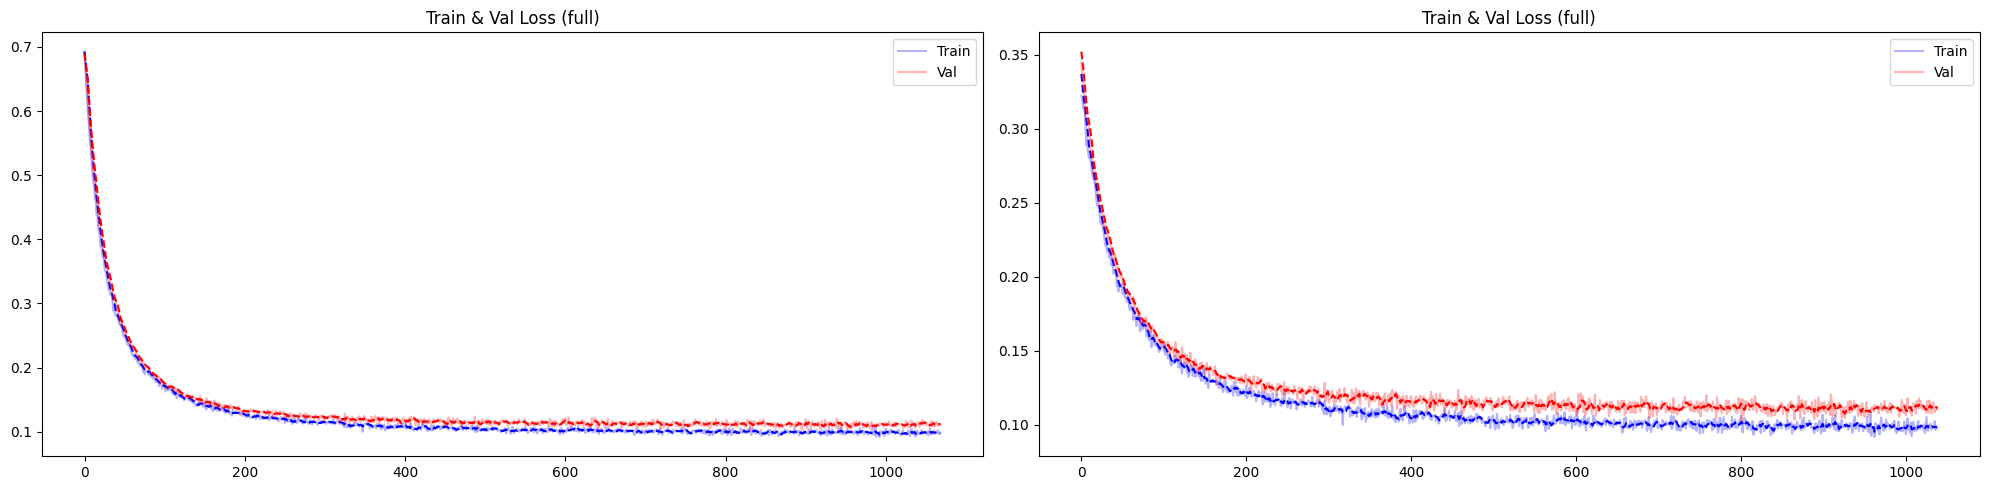

  5%|▌         | 48/889 [00:02<00:49, 17.13it/s]


KeyboardInterrupt: 

In [15]:
for epoch in range(n_epochs):
    for i, (imgs, attributs, classes) in tqdm(enumerate(train_loader), total=len(train_loader)):

        imgs, attributs, classes = imgs.to(device), attributs.to(device), classes.to(device)

        with torch.no_grad():
            # get the activation of the layer before the output
            x = resnet_minus_last_layer(imgs)
            x = x.view(x.shape[0], -1)  # flatten the output

            # put it in the sparse autoencoder
            x_hat, z = sae(x)

        # use z to predict the attributs
        attributs_pred = fully_connected(z)

        loss = criterion_fc(attributs_pred, attributs)

        optimizer_fc.zero_grad()
        loss.backward()
        optimizer_fc.step()




        if i % 10 == 0:
            train_loss_list.append(loss.item())

            # get val loss
            fully_connected.eval()
            with torch.no_grad():
                try:
                    imgs, attributs, classes = next(val_iterator)
                except StopIteration:
                    val_iterator = iter(val_loader)
                    imgs, attributs, classes = next(val_iterator)
                imgs, attributs, classes = imgs.to(device), attributs.to(device), classes.to(device)
                x = resnet_minus_last_layer(imgs)
                x = x.view(x.shape[0], -1)  # flatten the output
                x_hat, z = sae(x)
                attributs_pred = fully_connected(z)
                loss = criterion_fc(attributs_pred, attributs)
                val_loss_list.append(loss.item())
            fully_connected.train()



        if epoch % 1 == 0 and i % 200 == 0:

            start_idx = 30

            train_loss_list_smoothed = moving_average(train_loss_list, w=5)
            val_loss_list_smoothed = moving_average(val_loss_list, w=5)

            clear_output(wait=True)

            plt.figure(figsize=(20, 5))  # plus grand pour 8 sous-plots

            plt.subplot(1, 2, 1)
            plt.plot(train_loss_list, c="blue", alpha=0.3, label="Train")
            plt.plot(train_loss_list_smoothed, c="blue", linestyle='--')
            plt.plot(val_loss_list, c="red", alpha=0.3, label="Val")
            plt.plot(val_loss_list_smoothed, c="red", linestyle='--')
            plt.title("Train & Val Loss (full)")
            plt.legend()

            plt.subplot(1, 2, 2)
            plt.plot(train_loss_list[start_idx:], c="blue", alpha=0.3, label="Train")
            plt.plot(train_loss_list_smoothed[start_idx:], c="blue", linestyle='--')
            plt.plot(val_loss_list[start_idx:], c="red", alpha=0.3, label="Val")
            plt.plot(val_loss_list_smoothed[start_idx:], c="red", linestyle='--')
            plt.title("Train & Val Loss (full)")
            plt.legend()

            plt.tight_layout()
            plt.show()


In [ ]:
# # sauvegarder les poids du modèle et les paramètres d'entraînement

# torch.save({
#     'epoch': epoch+1,
#     'model_state_dict': fully_connected.to("cpu").state_dict(),
#     'optimizer_state_dict': optimizer_fc.state_dict(),
#     'loss': torch.tensor([train_loss_list_smoothed[-100:]]).mean(),
# }, f"weights/fully_connected_{crop_size}x{crop_size}_checkpoint2.pth")

In [19]:
print(sum(train_loss_list[-100:]) / 100)
print(sum(val_loss_list[-100:]) / 100)

0.09680210456252097
0.11016571596264839


In [21]:
print((attributs>0).sum().item()/attributs.numel())

0.037272135416666664


In [15]:
imgs, attributs, classes = next(iter(val_loader))

imgs, attributs, classes = imgs.to(device), attributs.to(device), classes.to(device)

# get the activation of the layer before the output
x = resnet_minus_last_layer(imgs)
x = x.view(x.shape[0], -1)  # flatten the output

# put it in the sparse autoencoder
x_hat, z = sae(x)

# use z to predict the attributs
attributs_pred = fully_connected(z)

1.1052969650648947e-09 0.036568883806467056 0.9999656677246094
1.1052969650648947e-09 0.036568883806467056 0.9999656677246094


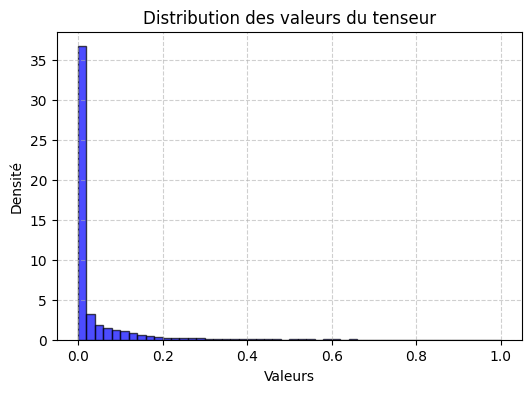

In [16]:
tensor = attributs_pred
print(tensor.min().item(), tensor.mean().item(), tensor.max().item())

tensor_non_nuls = tensor[tensor>0]
print(tensor_non_nuls.min().item(), tensor_non_nuls.mean().item(), tensor_non_nuls.max().item())

# Tracer un histogramme
plt.figure(figsize=(6,4))
plt.hist(tensor.detach().cpu().flatten().tolist(), bins=50, density=True, alpha=0.7, color="blue", edgecolor="black")
plt.title("Distribution des valeurs du tenseur")
plt.xlabel("Valeurs")
plt.ylabel("Densité")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

0.0 0.0372721366584301 1.0
1.0 1.0 1.0


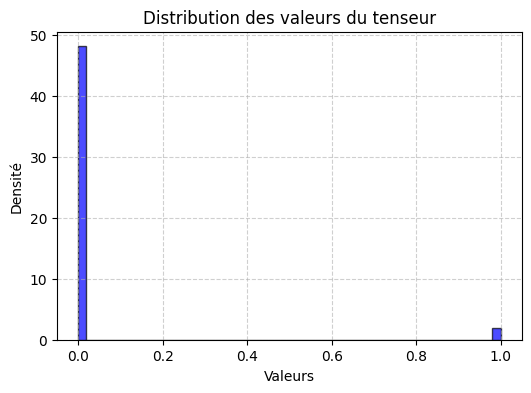

0.037272135416666664


In [17]:
tensor = attributs
print(tensor.min().item(), tensor.mean().item(), tensor.max().item())

tensor_non_nuls = tensor[tensor>0]
print(tensor_non_nuls.min().item(), tensor_non_nuls.mean().item(), tensor_non_nuls.max().item())

# Tracer un histogramme
plt.figure(figsize=(6,4))
plt.hist(tensor.detach().cpu().flatten().tolist(), bins=50, density=True, alpha=0.7, color="blue", edgecolor="black")
plt.title("Distribution des valeurs du tenseur")
plt.xlabel("Valeurs")
plt.ylabel("Densité")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

print((tensor>0).sum().item() / tensor.numel())  # pourcentage de valeurs non nulles dans le tenseur